In [1]:
import pypsa
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
%matplotlib inline

from synthseer import *
%load_ext autoreload
%autoreload 2

In [2]:
input_data = synth_data(2025, nyears=3, load_growth=0.2, excess_cap=1)

In [3]:
model = create_model_from_data(input_data, voll=5000, modular_expansion=True)

In [4]:
minpu, maxpu = model.components.Generator.get_bounds_pu()

In [5]:
model.components.Load

'Load' Components
-----------------
Attached to PyPSA Network 'Unnamed Network'
Components: 1

In [4]:
model.optimize()

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing integer variables.: 100%|████████████████| 1/1 [00:00<00:00, 475.92it/s]
INFO:linopy.io: Writing time: 5.55s


Running HiGHS 1.12.0 (git hash: n/a): Copyright (c) 2025 HiGHS under MIT licence terms
MIP linopy-problem-19wn5cz7 has 867270 rows; 420510 cols; 1498545 nonzeros; 15 integer variables (0 binary)
Coefficient ranges:
  Matrix  [2e-04, 1e+03]
  Cost    [5e+00, 5e+05]
  Bound   [0e+00, 0e+00]
  RHS     [3e-02, 2e+03]
Presolving model
247463 rows, 355129 cols, 797480 nonzeros  1s
247463 rows, 341719 cols, 784070 nonzeros  3s
Presolve reductions: rows 247463(-619807); columns 341719(-78791); nonzeros 784070(-714475) 

Solving MIP model with:
   247463 rows
   341719 cols (0 binary, 15 integer, 0 implied int., 341704 continuous, 0 domain fixed)
   784070 nonzeros

Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic;
     I => Shifting; J => Feasibility jump; L => Sub-MIP; P => Empty MIP; R => Randomized rounding;
     S => Solve LP; T => Evaluate node; U => Unbounded; X => User solution; Y => HiGHS solution;
     Z => ZI Round; l => Trivial lower; p => Trivial po

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 420510 primals, 867270 duals
Objective: 1.40e+09
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-ext-p-lower, Generator-ext-p-upper were not assigned to the network.


('ok', 'optimal')

/Users/mohini/Documents/repos/rhiza/seer/synthseer.py:293: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



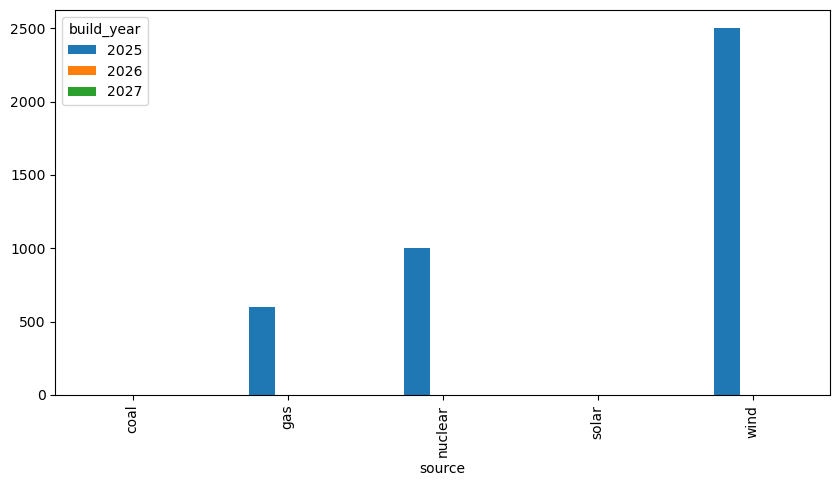

In [5]:
viz_model(model)

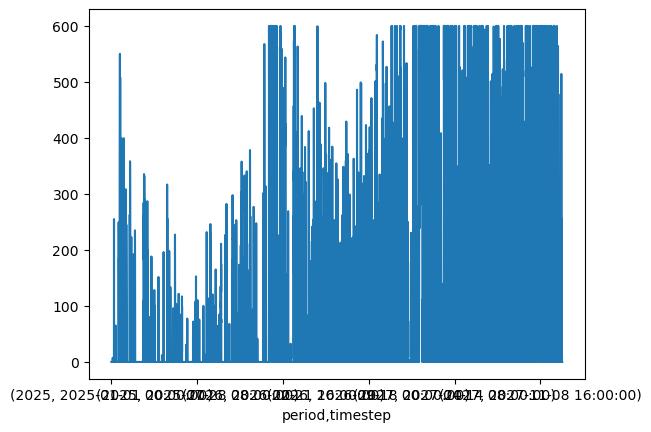

In [6]:
model.generators_t.p["gas - 0_2025"].plot()
plt.show()

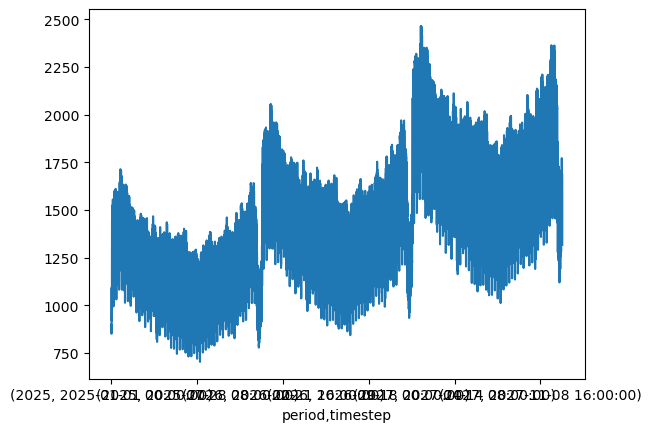

In [46]:
model.loads_t.p["load - 0"].plot()
plt.show()